# ÖDEV 4 EK

## 2)

Nedensel bir DZD sistemin sistem fonksiyonu $H(z)=\frac{z^2}{(z+1)(z-1)^2}$ olarak verilmektedir. Dürtü cevabını önce el ile bulunuz. Daha sonra ise Örnek 7 ve Örnek $8^{\prime}$ de gösterildiği gibi iki farklı yöntemle bu sistemin dürtü cevabını bulunuz ve çizdiriniz ve Örnek 9'da gösterildiği gibi sonuçları karşılaştırını. Elde ettiğiniz bu sonuçlar birbiri ile örtüşüyor mu? El ile bulduğunuz sonuç ile de ayrıca karşılaştırınız.


In [48]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as sgnl


def get_z_transform_from_residuez(r,p,k,floating_point = 2):
    xz = ""
    for i in range(len(p)):
        count = 1
        if (i>0 and p[i] == p[i-1] ):
            count += 1
        else:
            count = 1
        xz += "({:.{}f})/(1-({:.{}f})z^-1)^{}".format(r[i],floating_point,p[i],floating_point,count)
        if i < len(p)-1:
            xz += " + "
    for i in range(len(k)):
        if i == 0:
            xz += " + "
        xz += "({:.{}f})z^-{}".format(k[i],floating_point,i)
        if i < len(k)-1:
            xz += " + "
    return xz
def represent_z_tf_positive(b,a, floating_point = 2):
    xz = ""
    for i in range(len(b)):
        xz += "({:.{}f})z^{}".format(b[i],floating_point,len(b)-i-1)
        if i < len(b)-1:
            xz += " + "
    xz += "\n"
    for i in range(len(a)):
        xz += "({:.{}f})z^{}".format(a[i],floating_point,len(a)-i-1)
        if i < len(a)-1:
            xz += " + "
    return xz

def represent_z_tf_negative(b,a,floating_point = 2):
    if len(b) < len(a):
        b = np.append(np.zeros(len(a)-len(b)),b)
    xz = ""
    for i in range(len(b)):
        xz += "({:.{}f})z^-{}".format(b[i],floating_point,i)
        if i < len(b)-1:
            xz += " + "
    xz += "\n"
    for i in range(len(a)):
        xz += "({:.{}f})z^-{}".format(a[i],floating_point,i)
        if i < len(a)-1:
            xz += " + "
    return xz , b , a

z = np.array([0,0])
p = np.array([1,1,-1])
b,a = sgnl.zpk2tf(z,p,1)
print("b:",b,"a:",a)
print("\nxz positive:")
xz_positive = represent_z_tf_positive(b,a,2 )
print(xz_positive)

print("\nxz Negative: ")
xz_negative , b_negative , a_negative = represent_z_tf_negative(b,a,2)
print(xz_negative)

r, p, k = sgnl.residuez(b_negative,a_negative) 
xz_simple_frac = get_z_transform_from_residuez(r,p,k)
print("\nSimple fraction form of the Z-transform:")
print(xz_simple_frac)
print("r:",r,"p:",p,k)





b: [1. 0. 0.] a: [ 1. -1. -1.  1.]

xz positive:
(1.00)z^2 + (0.00)z^1 + (0.00)z^0
(1.00)z^3 + (-1.00)z^2 + (-1.00)z^1 + (1.00)z^0

xz Negative: 
(0.00)z^-0 + (1.00)z^-1 + (0.00)z^-2 + (0.00)z^-3
(1.00)z^-0 + (-1.00)z^-1 + (-1.00)z^-2 + (1.00)z^-3

Simple fraction form of the Z-transform:
(-0.25+0.00j)/(1-(1.00+0.00j)z^-1)^1 + (0.50+0.00j)/(1-(1.00+0.00j)z^-1)^2 + (-0.25+0.00j)/(1-(-1.00+0.00j)z^-1)^1
r: [-0.25+0.j  0.5 +0.j -0.25+0.j] p: [ 1.+0.j  1.+0.j -1.+0.j] []


### Dimpulse ile Ters z dönüşümünü alalım

/opt/anaconda3/lib/python3.9/site-packages/scipy/signal/filter_design.py:1631: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  warnings.warn("Badly conditioned filter coefficients (numerator): the "


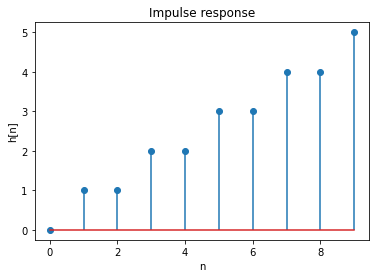

In [49]:
num = np.array(b_negative)
denum = np.array(a_negative)
n,h = sgnl.dimpulse((num,denum,1),x0 = 0,n=10)
h = np.squeeze(h)
#plot n and h
plt.stem(n,h)
plt.title("Impulse response")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.show()


### El ile 2inci sorunun çözümü 

Ódev $4 \mathbb{E R}$

2) 

$$
\begin{aligned}
& H(z)=\frac{z^{2}}{(z+1)(z-1)^{2}} \\
& H(z)=\frac{-0,25}{1-z^{-1}}+\frac{0,5}{\left(1-z^{-1}\right)^{2}}-\frac{0,25}{\left(1+z^{-1}\right)}
\end{aligned}
$$

From the 2 transform table:

$$
\begin{array}{lll}
a^{n} u[n] & \longleftrightarrow \frac{1}{1-a z^{-1}} & |z|>|a| \\
n a^{n} u[n] & \longleftrightarrow \frac{a z^{-1}}{\left(1-a z^{-1}\right)^{2}} & |z|>|a|
\end{array}
$$

And from properties

$$
\begin{aligned}
& x\left[n-n_{0}\right] \longleftrightarrow z^{-n_{0} x(z)} \\
& \text { so } \frac{0,5}{\left(1-z^{-1}\right)^{2}}=0,5\left(\frac{z^{-1}}{\left(1-z^{-1}\right)^{2}}\right) z \longleftrightarrow 0,5(n+1) u[n+1] \\
& \Rightarrow h[n]=-0,25 u[n]+0,5(n+1) u[n+1]-0,25(-1)^{n} u[n]
\end{aligned}
$$

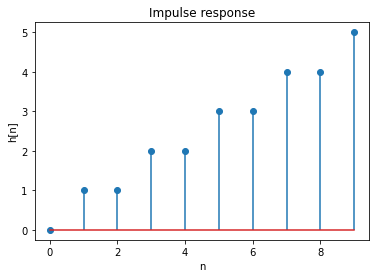

In [50]:
def u(n):
    return np.where(n>=0,1,0)
n = np.arange(0,10)
hel = -0.25* u(n) + 0.5*(n+1)*u(n+1) - 0.25*((-1)**n)*u(n)
#plot n and h
plt.stem(n,np.squeeze(hel))
plt.title("Impulse response")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.show()


### KARŞILAŞTIRMA

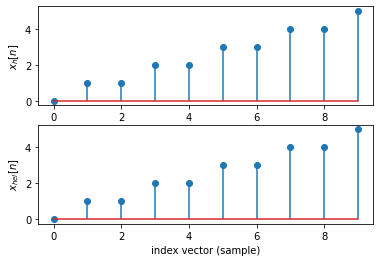

In [51]:
plt.subplot(2,1,1), plt.stem(n, h), plt.ylabel('$x_{h}[n]$') 
plt.subplot(2,1,2), plt.stem(n, hel), plt.ylabel('$x_{hel}[n]$') 
plt.xlabel('index vector (sample)')
plt.show()

## 3)

İkinci soruyu $H(z)=\frac{1+3 z^{-1}+\frac{11}{6} z^{-2}+\frac{1}{3} z^{-3}}{1+\frac{5}{6} z^{-1}+\frac{1}{6} z^{-2}}$ için tekrar ediniz.


### 3. soru el ile h[n]'in bulunması

In [52]:
num = np.array([1,3,11/6,1/3])
denum = np.array([1,5/6,1/6,0])
r, p, k = sgnl.residuez(num,denum) 
print("r:",r,"p:",p,"k:",k)
xz_simple_frac = get_z_transform_from_residuez(r,p,k,5)
print("Simple fraction form of the Z-transform:")
print(xz_simple_frac)




r: [ 1. -1.] p: [-0.33333333 -0.5       ] k: [1. 2.]
Simple fraction form of the Z-transform:
(1.00000)/(1-(-0.33333)z^-1)^1 + (-1.00000)/(1-(-0.50000)z^-1)^1 + (1.00000)z^-0 + (2.00000)z^-1


$$
\begin{aligned}
& H(z)=\frac{1+3 z^{-1}+\frac{11}{6} z^{-2}+\frac{1}{3} z^{-3}}{1+\frac{9}{6} z^{-1}+\frac{1}{6} z^{-2}} \\
& H(z)=\frac{1}{1+\frac{1}{3} z^{-1}}-\frac{1}{1+\frac{1}{2} z^{-1}}+1+2 z^{-1}
\end{aligned}
$$

$a^{n} u[n] \longleftrightarrow \frac{1}{1-a z^{-1}}$ and $x\left[n-n_{0}\right] \longleftrightarrow z^{-n_{0}} X(z)$

$$
h[n]=\left(-\frac{1}{3}\right)^{n} u[n]-\left(-\frac{1}{2}\right)^{n} u[n]+S[n]+2 S[n-1]
$$


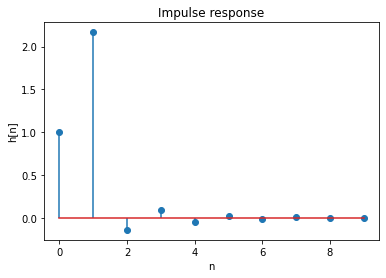

In [53]:
def u(n):
    return np.where(n >= 0, 1, 0)
def dirac(n):
    return np.where(n == 0, 1, 0)
n = np.arange(0,10)

hel = (-1/3)**n * u(n) - (-1/2)**n * u(n) +dirac(n) + 2 * dirac(n-1)
#plot n and h
plt.stem(n,hel)
plt.title("Impulse response")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.show()

### 3. soru kod ile h[n]'in bulunması

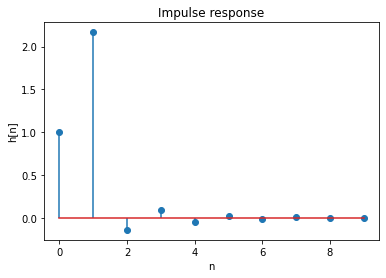

In [54]:
n,h = sgnl.dimpulse((num,denum,1),x0 = 0,n=10)
h = np.squeeze(h)
#plot n and h
plt.stem(n,h)
plt.title("Impulse response")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.show()

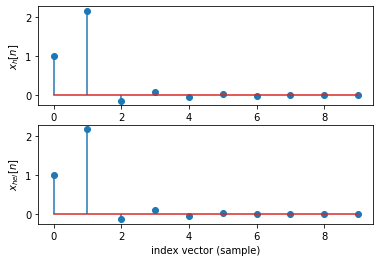

In [55]:
plt.subplot(2,1,1), plt.stem(n, h), plt.ylabel('$x_{h}[n]$') 
plt.subplot(2,1,2), plt.stem(n, hel), plt.ylabel('$x_{hel}[n]$') 
plt.xlabel('index vector (sample)')
plt.show()

## 4)

İkinci soruyu $H(z)=\frac{10\left(1-\frac{1}{\sqrt{2}} z^{-1}\right)}{\left(1-e^{j \frac{\pi}{4} } z^{-1} \right)\left(1-e^{-j \frac{\pi}{4}} z^{-1}\right)\left(1-0.5 z^{-1}\right)}$ için tekrar ediniz.


In [56]:
#$H(z)=\frac{10\left(1-\frac{1}{\sqrt{2}} z^{-1}\right)}{\left(1-e^{j \frac{\pi}{4} z^{-1}}\right)\left(1-e^{-j \frac{\pi}{4}} z^{-1}\right)\left(1-0.5 z^{-1}\right)}$
z = np.array([0,0, 1/np.sqrt(2)])
p = np.array([np.exp(1j*np.pi/4),np.exp(-1j*np.pi/4),0.5])
gain = 10  
b,a = sgnl.zpk2tf(z,p,gain)
print("\nX(z) positive:")
xz_positive = represent_z_tf_positive(b,a,2 )
print(xz_positive)

print("\nX(z) Negative: ")
xz_negative , b_negative , a_negative = represent_z_tf_negative(b,a,2)
print(xz_negative)

r, p, k = sgnl.residuez(b_negative,a_negative) 
xz_simple_frac = get_z_transform_from_residuez(r,p,k)
print("\nSimple fraction form of the Z-transform:")
print(xz_simple_frac)



X(z) positive:
(10.00)z^3 + (-7.07)z^2 + (0.00)z^1 + (0.00)z^0
(1.00)z^3 + (-1.91)z^2 + (1.71)z^1 + (-0.50)z^0

X(z) Negative: 
(10.00)z^-0 + (-7.07)z^-1 + (0.00)z^-2 + (0.00)z^-3
(1.00)z^-0 + (-1.91)z^-1 + (1.71)z^-2 + (-0.50)z^-3

Simple fraction form of the Z-transform:
(-1.91+0.00j)/(1-(0.50+0.00j)z^-1)^1 + (5.95-3.26j)/(1-(0.71+0.71j)z^-1)^1 + (5.95+3.26j)/(1-(0.71-0.71j)z^-1)^1


$$
\begin{aligned}
H(z)= & \frac{10\left(1-\frac{1}{\sqrt{2}} z^{-1}\right)}{\left(1-e^{j n / 4} z^{-1}\right)\left(1-e^{-j \pi / 4} z^{-1}\right)\left(1-0,5 z^{-1}\right)} \\
= & \frac{-1,91}{1-0,5 z^{-1}}+\frac{5,95-j 3,26}{1-(0,71+j 0,71) z^{-1}}+\frac{5,95+j 3,26}{1-(0,71-j 0,71) z^{-1}} \\
= & -1,91(0,5)^{n} u[n]+(5,95-j 3,26)\left(e^{j \pi / 4}\right)^{n} u[n] \\
& +(5,95+j 3,26)\left(e^{-j\pi / 4}\right)^{n} u[n]
\end{aligned}
$$

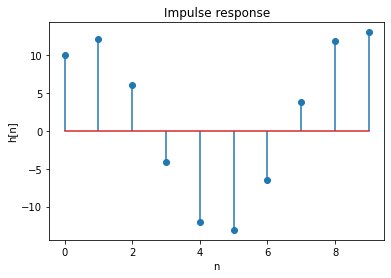

In [61]:
num = np.array(b_negative)
denum = np.array(a_negative)
n,h = sgnl.dimpulse((num,denum,1),x0 = 0,n=10)
h = np.squeeze(h)
#plot n and h
plt.stem(n,h)
plt.title("Impulse response")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.show()

### el ile çözüm

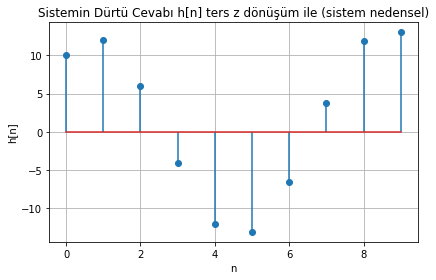

In [62]:
hn = 0
for i in range(len(r)):
    hn += np.real(r[i] * p[i]**n) * u(n)
plt.stem(n, hn)
plt.xlabel('n')
plt.ylabel('h[n]')
plt.title('Sistemin Dürtü Cevabı h[n] ters z dönüşüm ile (sistem nedensel)')
plt.grid(True)
plt.tight_layout()
plt.show()  

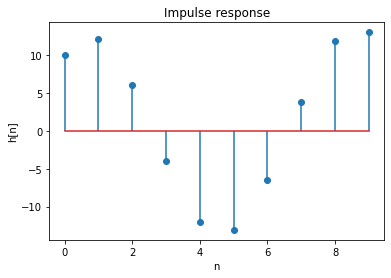

In [63]:
n = np.arange(0,10)
hel = -1.91* (0.5**n) + (5.95-3.26j)* (np.exp((1j*np.pi/4)) )**n +(5.95+3.26j)* (np.exp((-1j*np.pi/4)) )**n 
#plot
plt.stem(n,np.real((hel)))
plt.title("Impulse response")
plt.xlabel("n")
plt.ylabel("h[n]")
plt.show()


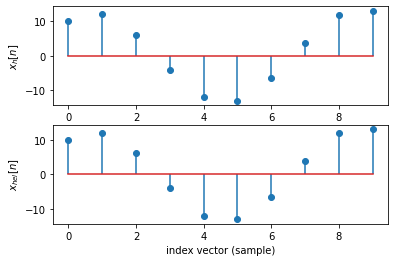

In [65]:
plt.subplot(2,1,1), plt.stem(n, np.real(h)), plt.ylabel('$x_{h}[n]$') 
plt.subplot(2,1,2), plt.stem(n, np.real(hel)), plt.ylabel('$x_{hel}[n]$') 
plt.xlabel('index vector (sample)')
plt.show()

## 5)

Bu ödevin size kazandırdıklarını özetleyiniz (en az 5 cümle, en az 256 karakter).



Bu ödev sayesinde python ile Ztransform anlizi nasıl yapılabileceğini öğrendim. Z domainindeki fonksiyonlar gösterim şekilleri arasındaki geçişleri (Basit kesirlere ayırma, sıfırları ve kutupları bulma, TF haline dönüştürme) python ile yapmaya öğrendim. Ayrınca pthon ile terz z dönüşü almayı de öğrendim. Sistem fonksiyonun ROC'una bakarak sistemin özelliklerini (nedensel , kararlı) yorumlamayı öğrendim.

Aşağıdaki sorulara çalışınız. Ödev-3 EK'in parçası olarak teslim edilMeyecektir:<br>



6) Birinci, ikinci ve üçüncü soruda verilen sistemlere Örnek-10'daki giriş işareti uygulandığında sistemin çıkışında elde edilecek işareti çizdiriniz.

7) İkinci soruyu ROC: nedensel olmayan sistem için tekrar ediniz, sistemin nedensel olmadığını düşünerek dürtü cevabııı bulunuz.


8) Üçüncü soruyu, $p_1$ ve $p_2$ sistemin kutuları olmak üzere, $\left|p_1\right|<\left|p_2\right|$, 7a) ROC: $\left|p_1\right|<|z|<\left|p_2\right|$ ve $7 b)|z|<\left|p_1\right|$ için tekrar ediniz. Bütün bu olası durumlar için sistemin kararlılığını ve nedenselliğini tartışınız.